[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AGRIdigital-Climbat/PlantillaMapa/blob/main/06_Humedad_Suelo/01_humedad_suelo.ipynb)

# Humedad de suelo: estado, percentiles y anomalia (SMAP)
## PROSUCO - CLIMBAT | Analisis por municipio de Bolivia (GEE + Colab)

> **Area de estudio = tu GeoJSON.** Este notebook usa por defecto:
>
> `RUTA_AOI = "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"` (compartido `Cualquiera con el enlace`).
> El GeoJSON **siempre manda**: al cargarse, `roi`, `ZONA['bbox']`, `ZONA['centro']`
> y `area_km2` se recalculan desde el poligono. El `bbox` de CONFIG solo es respaldo
> si cambias a `AOI_MODE = "bbox"`.

**Orden de ejecucion:** 1) Instalacion -> 2) Autenticacion GEE (`EE_PROJECT`) ->
3) CONFIG (anos + satelite + umbrales) -> 4) AOI desde Drive -> 5) celdas del modulo.
Solo edita la celda **CONFIGURACION MAESTRA**.


In [1]:
# ============================================================
# 1.1 Instalación de librerías (ejecutar una sola vez en Colab)
# ============================================================

import importlib
import subprocess
import sys


def _asegurar(paquete, modulo=None):
    """Instala el paquete solo si no está disponible."""
    try:
        importlib.import_module(modulo or paquete)
    except ImportError:
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", paquete]
        )


_asegurar("earthengine-api", "ee")
_asegurar("geemap")
_asegurar("geopandas")
_asegurar("pandas")
_asegurar("numpy")
_asegurar("matplotlib")

import ee
import geemap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

print("Librerías listas.")
print("earthengine-api:", ee.__version__)
print("geemap:", geemap.__version__)

Librerías listas.
earthengine-api: 1.7.39
geemap: 0.38.8


In [2]:
# ============================================================
# 1.2 Autenticación en Google Earth Engine
# ============================================================
# >>> REEMPLAZAR por el id del proyecto de Cloud de PROSUCO/CLIMBAT <<<

EE_PROJECT = "gen-lang-client-0636031685"

ee.Authenticate()
ee.Initialize(project=EE_PROJECT)

print("Earth Engine inicializado correctamente.")
print("Proyecto:", EE_PROJECT)

Earth Engine inicializado correctamente.
Proyecto: gen-lang-client-0636031685


## Configuración maestra

> **✏️ Esta es la única celda que se edita para diagnosticar una zona nueva.**

| Bloque | Qué define | Verificación previa |
|---|---|---|
| `ZONA` | nombre, bbox `[oeste, sur, este, norte]` y punto de vista | dibujar en [geojson.io](https://geojson.io) o en el editor GEE y copiar coordenadas |
| `AOI_MODE`/`RUTA_AOI` | fuente del AOI: `"bbox"` o `"auto"` (polígono **GeoJSON**) | exportar el polígono desde QGIS como **GeoJSON**; en `RUTA_AOI` se puede pegar un **enlace de Google Drive** (el notebook lo descarga solo) o una ruta de Drive |
| `PUNTOS_LOCALES` | manantiales/bofedales del saber local | levantamiento con las comunidades |
| `FECHA_INICIO / FECHA_FIN` | ventana analítica (**30+ años**) | default 1996-01-01 → 2026-12-31 |
| `CALENDARIO` | meses de siembra/cosecha y estación seca | observadores Yapuchiri |
| `UMBRALES` | todos los cortes analíticos en un solo lugar | criterio técnico + experiencia local |
| `ESCALAS` | resolución de cómputo (m); subir si la zona es grande | — |

In [3]:
# ===========================================================================
# CONFIGURACIÓN MAESTRA — ÚNICA CELDA QUE SE EDITA PARA CADA ZONA
# ===========================================================================

# --- 1. Zona de intervención ------------------------------------------------
# Fuente del AOI:
#   "bbox" -> usa el rectángulo ZONA["bbox"] de abajo (rápido, sin Drive)
#   "auto" -> usa un polígono .geojson. RUTA_AOI admite 3 formas:
#       * Enlace o ID de Google Drive  -> se DESCARGA solo (no subes nada a mano)
#           "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"
#           "11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N"
#       * Ruta en tu Drive ya montado  -> se lee directo, SIN copiar a /content
#           "/content/drive/MyDrive/CLIMBAT/zona.geojson"
#       * Carpeta en Drive             -> toma el único .geojson que contenga
#           "/content/drive/MyDrive/CLIMBAT"
AOI_MODE = "auto"
RUTA_AOI = "https://drive.google.com/file/d/11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N/view?usp=sharing"

ZONA = {
    # Coordenadas geocodificadas: Escoma (La Paz, Bolivia) ~3832 msnm
    # (solo se usan como respaldo cuando AOI_MODE = "bbox")
    "nombre": "Escoma, La Paz (prueba)",
    "bbox": [-69.33, -15.86, -68.93, -15.46],   # [oeste, sur, este, norte]
    "centro": [-69.1289, -15.6615],             # punto de vista del mapa
    "zoom": 10,
}

# --- 2. Puntos levantados con comunidades (saber local) ---------------------
# Listas de [longitud, latitud]. Dejar vacías si aún no hay levantamiento.
PUNTOS_LOCALES = {
    "manantiales": [],
    "bofedales": [],
}

# --- 3. Ventana analítica: 30+ años hacia atrás desde el año actual ---------
# Regla de la plantilla: 1996-01-01 -> 2026-12-31 (todo análisis de rango de años usa esta).
# Los datasets usan su período nativo si es mayor: CHIRPS 1981+ · ERA5-Land 1950+
# · JRC 1984–2021 · MODIS 2000+ (NDVI) / 2001+ (MCD12Q1 agricultura) · SMAP 2015+
FECHA_INICIO = "1996-01-01"
FECHA_FIN = "2026-12-31"

# --- 4. Calendario agrícola local (verificar con observadores Yapuchiri) ----
CALENDARIO = {
    "siembra": 11,       # mes de siembra (1–12)
    "cosecha": 4,        # mes de cosecha (1–12)
    "meses_estacion_seca": [5, 6, 7, 8, 9, 10],   # se usa en M10 (bofedales)
}

# --- 5. Umbrales analíticos (ajustar con criterio técnico y local) ----------
UMBRALES = {
    "helada_c": 0.0,               # °C mínima para contar un día de helada (M4)
    "helada_grave_c": -2.0,        # °C de helada grave (daño severo) (M4)
    "mes_seco_mm": 30.0,           # mm/mes para clasificar mes seco (M2)
    "spi_severo": -1.5,            # umbral de sequía severa SPI-3 (M5)
    "ndvi_anomalia_z": -1.5,       # anomalía NDVI severa (M7)
    "manantial_occurrencia": 100,  # % ocurrencia JRC mínima (M9)
    "manantial_drenaje_max": 50,   # celdas acumuladas máx. (cabeceras) (M9)
    "bofedal_altitud_min": 3000,   # msnm mínimo (M10)
    "bofedal_altitud_max": 5200,   # msnm máximo (M10)
    "bofedal_pendiente_max": 5.0,  # grados de pendiente máxima (M10)
    "bofedal_seasonality": 8,      # meses con agua JRC mínimos (M10)
    "bofedal_ndvi_seco": 0.25,     # NDVI mínimo en estación seca (M10)
    "clases_agricolas": [12, 14],  # LC_Type1 MCD12Q1: 12=cultivos, 14=mosaico (M11)
}

# --- 6. Escalas de cómputo (metros) -----------------------------------------
# Subir si la zona es muy grande (más rápido, menos detalle)
ESCALAS = {"clima": 5000, "modis": 250, "jrc": 90, "detalle": 30}
TILE_SCALE = 4

# ===========================================================================
# A partir de aquí no se edita nada
# ===========================================================================

MESES = list(range(1, 13))
MESES_ES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
            "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

roi = None   # se construye en la celda 1.4 (bbox o GeoJSON según AOI_MODE)
centro = None
ANIO_INI = int(FECHA_INICIO[:4])
ANIO_FIN = int(FECHA_FIN[:4])

# Años COMPLETOS (se excluye el año en curso de métricas y mapas anuales)
ANIOS_COMPLETOS = list(range(ANIO_INI, ANIO_FIN))
FILTRO_ANIOS_COMPLETOS = ee.Filter.calendarRange(
    ANIOS_COMPLETOS[0], ANIOS_COMPLETOS[-1], "year"
)

print("Zona:", ZONA["nombre"])
print("Ventana analítica:", FECHA_INICIO, "->", FECHA_FIN,
      f"({ANIO_FIN - ANIO_INI + 1} años calendario)")
print("Años completos para métricas:", ANIOS_COMPLETOS[0], "-", ANIOS_COMPLETOS[-1])
print("Calendario: siembra mes", CALENDARIO["siembra"],
      "| cosecha mes", CALENDARIO["cosecha"])
print("Umbrales activos:", UMBRALES)

Zona: Escoma, La Paz (prueba)
Ventana analítica: 1996-01-01 -> 2026-12-31 (31 años calendario)
Años completos para métricas: 1996 - 2025
Calendario: siembra mes 11 | cosecha mes 4
Umbrales activos: {'helada_c': 0.0, 'helada_grave_c': -2.0, 'mes_seco_mm': 30.0, 'spi_severo': -1.5, 'ndvi_anomalia_z': -1.5, 'manantial_occurrencia': 100, 'manantial_drenaje_max': 50, 'bofedal_altitud_min': 3000, 'bofedal_altitud_max': 5200, 'bofedal_pendiente_max': 5.0, 'bofedal_seasonality': 8, 'bofedal_ndvi_seco': 0.25, 'clases_agricolas': [12, 14]}


In [4]:
# ============================================================
# 1.3 Utilidades comunes (reutilizadas por todos los módulos)
# ============================================================

# Parámetros de reducción seguros contra "User memory limit exceeded":
#   bestEffort=True -> GEE sube la escala automáticamente si no cabe en memoria.
#   tileScale=8     -> divide el cálculo en tiles más pequeños (menos memoria c/u).
REDUCIR = dict(maxPixels=1e9, tileScale=8, bestEffort=True)
REDUCIR_AREA = dict(maxPixels=1e10, tileScale=16, bestEffort=True)


def apilar(imagenes, nombres):
    """Une imágenes de una banda en una sola imagen multibanda."""
    pila = None
    for img, nombre in zip(imagenes, nombres):
        banda = ee.Image(img).select(0).rename(nombre)
        pila = banda if pila is None else pila.addBands(banda)
    return pila


def reducir_bandas(imagenes, nombres, escala, tam=6, reductor=None, params=None):
    """reduceRegion de muchas bandas EN BLOQUES (una petición por bloque).

    Evita el error de memoria que ocurre al reducir de una sola vez una imagen
    con decenas de bandas (cada banda puede depender de cientos/miles de imágenes
    diarias). Devuelve un dict {nombre_banda: valor}.
    """
    reductor = reductor or ee.Reducer.mean()
    params = params or REDUCIR
    salida = {}
    for i in range(0, len(imagenes), tam):
        pila = apilar(imagenes[i:i + tam], nombres[i:i + tam])
        salida.update(
            pila.reduceRegion(reductor, roi, escala, **params).getInfo()
        )
    return salida


def composite_mensual(coleccion, anios, banda=None):
    """Reduce una colección diaria a UN compuesto por año-mes (una imagen c/u).

    Aligera ~30x la memoria de las climatologías de 30 años. `anios` debe listar
    solo años con dato (evita colecciones vacías). Con `banda`, deja una sola banda.
    """
    imgs = []
    for y in anios:
        for m in MESES:
            i0 = f"{y}-{m:02d}-01"
            i1 = (pd.Timestamp(i0) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
            sub = coleccion.filterDate(i0, i1)
            if banda:
                sub = sub.select(banda)
            imgs.append(sub.mean().set("system:time_start", ee.Date(i0).millis()))
    return ee.ImageCollection(imgs)


def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente).

    Evita que el relleno de color tape el mapa y meta ruido en la interpretación;
    deja el límite del área bien visible por encima de las demás capas.
    """
    return roi.style(color=color, fillColor="00000000", width=ancho)


def promediar_aoi(imagen, banda, escala):
    """Promedio de una banda dentro del AOI -> valor Python (o None)."""
    d = (
        imagen.select(banda)
        .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        .getInfo()
    )
    return d.get(banda)


def serie_aoi(coleccion, banda, escala, bloque_anios=5):
    """Extrae el promedio del AOI por imagen, EN BLOQUES de años.

    Procesar la serie completa de una vez agota la memoria; por eso se trocea
    (por defecto cada 5 años) y se concatenan los resultados.
    """
    registros = []

    def _una_imagen(img):
        st = (
            img.select(banda)
            .reduceRegion(ee.Reducer.mean(), roi, escala, **REDUCIR)
        )
        return ee.Feature(None, {
            "date": ee.Date(img.get("system:time_start")).format("yyyy-MM-dd"),
            "valor": st.get(banda),
        })

    for y0 in range(ANIO_INI, ANIO_FIN + 1, bloque_anios):
        y1 = min(y0 + bloque_anios - 1, ANIO_FIN)
        sub = coleccion.filterDate(f"{y0}-01-01", f"{y1 + 1}-01-01")
        fc = ee.FeatureCollection(sub.map(_una_imagen)).getInfo()
        registros += [f["properties"] for f in fc["features"]]
    return registros


print("Utilidades: apilar(), reducir_bandas(), composite_mensual(), "
      "promediar_aoi(), serie_aoi()")

Utilidades: apilar(), reducir_bandas(), composite_mensual(), promediar_aoi(), serie_aoi()


In [5]:
# ============================================================
# 1.4 Área de estudio (AOI) y mapa base
# ============================================================
# Fuente del AOI (ver CONFIG):
#   AOI_MODE = "bbox" -> rectángulo ZONA["bbox"].
#   AOI_MODE = "auto" -> polígono desde un archivo .geojson en Google Drive.
#                        (En QGIS: Exportar -> Guardar entidades como -> GeoJSON,
#                         CRS EPSG:4326; subir a Drive y ajustar RUTA_AOI.)

def borde_aoi(color="FF0000", ancho=2):
    """Capa de SOLO el borde del AOI (relleno transparente)."""
    # ee.Geometry NO tiene .style() en la API de Python -> se envuelve en FeatureCollection
    fc = ee.FeatureCollection([ee.Feature(roi)])
    return fc.style(color=color, fillColor="00000000", width=ancho)


if AOI_MODE == "auto":
    from google.colab import drive
    drive.mount("/content/drive")

    import os
    import re
    import glob
    import geopandas as gpd

    ruta = str(RUTA_AOI).strip()

    # (a) Enlace o ID de Google Drive -> descarga automática (sin subir nada a mano).
    #     El archivo debe estar compartido como "Cualquiera con el enlace".
    if ruta.startswith("http") or ("/" not in ruta and len(ruta) >= 20):
        _asegurar("gdown")
        import gdown

        m = re.search(r"(?:/d/|id=)([-\w]{20,})", ruta)
        fid = m.group(1) if m else ruta
        ext = (
            ".zip" if ruta.lower().endswith(".zip") else
            ".kml" if ruta.lower().endswith(".kml") else
            ".gpkg" if ruta.lower().endswith(".gpkg") else
            ".geojson"
        )
        destino = "/content/zona_aoi" + ext
        print("Descargando AOI desde Google Drive...")
        gdown.download(id=fid, output=destino, quiet=False)
        ruta = destino
    # (b) Carpeta en Drive -> usar el único .geojson que contenga
    elif os.path.isdir(ruta):
        cands = sorted(glob.glob(os.path.join(ruta, "*.geojson")))
        if not cands:
            raise FileNotFoundError(f"No se encontró ningún .geojson en {ruta}")
        ruta = cands[0]
    # (c) Ruta de archivo en el Drive montado -> se lee directo (sin copiar)

    gdf = gpd.read_file(ruta).to_crs(4326)
    try:
        geometria = gdf.geometry.union_all()      # shapely >= 2 (disuelve features)
    except AttributeError:
        geometria = gdf.geometry.unary_union      # shapely < 2
    gdf = gpd.GeoDataFrame(geometry=[geometria], crs=4326)

    roi = geemap.geopandas_to_ee(gdf).geometry()

    minx, miny, maxx, maxy = geometria.bounds
    ZONA["bbox"] = [minx, miny, maxx, maxy]
    ZONA["centro"] = [(minx + maxx) / 2, (miny + maxy) / 2]
    ZONA["zoom"] = 10
    print("AOI cargado desde:", ruta)
else:
    roi = ee.Geometry.Rectangle(ZONA["bbox"], proj="EPSG:4326", geodesic=False)

centro = ee.Geometry.Point(ZONA["centro"])
area_km2 = roi.area(maxError=1e6).divide(1e6).getInfo()

Map_aoi = geemap.Map()
Map_aoi.centerObject(roi, ZONA["zoom"])
Map_aoi.add_basemap("HYBRID")
Map_aoi.addLayer(borde_aoi(), {}, f"AOI: {ZONA['nombre']}")

# Puntos del saber local (si se cargaron en CONFIG)
for tipo, color in (("manantiales", "cyan"), ("bofedales", "magenta")):
    coords = PUNTOS_LOCALES.get(tipo, [])
    if coords:
        Map_aoi.addLayer(
            ee.Geometry.MultiPoint(coords),
            {"color": color},
            f"{tipo.capitalize()} (saber local)",
        )

print(f"Zona: {ZONA['nombre']}")
print(f"Área del AOI: {area_km2:,.1f} km²")
print(f"Extensión (bbox): {ZONA['bbox']}")
print("Puntos de saber local cargados:",
      {k: len(v) for k, v in PUNTOS_LOCALES.items()})

Map_aoi

Mounted at /content/drive
Descargando AOI desde Google Drive...


Downloading...
From: https://drive.google.com/uc?id=11k-2-0MfG84QcYld7XY3r5XVMDHWtJ0N
To: /content/zona_aoi.geojson
100%|██████████| 6.32k/6.32k [00:00<00:00, 11.4MB/s]


AOI cargado desde: /content/zona_aoi.geojson
Zona: Escoma, La Paz (prueba)
Área del AOI: 5,638.9 km²
Extensión (bbox): [-68.088142, -19.88671, -67.170426, -19.050138]
Puntos de saber local cargados: {'manantiales': 0, 'bofedales': 0}


Map(center=[-19.436538457151894, -67.61413826547428], controls=(WidgetControl(options=['position', 'transparen…

# M6. Humedad de suelo: estado actual, percentiles y anomalía
**Dimensiones:** *ocurrencia* (meses secos), *intensidad* (percentil/anomalía),
*duración* (racha de meses secos), *tendencia* (serie mensual).

* **Primario:** `NASA/SMAP/SPL4SMGP/008` — humedad radicular (`sm_rootzone`, fracción 0–1),
  percentil (`sm_rootzone_pctl`, 0–100) y anomalía (`sm_surface_anomaly`) del satélite SMAP.
  **Período nativo: 2015–actual** (se declara explícitamente; no se rellenan años sin dato).
* **Alternativa para la ventana completa de 30 años:** capas de suelo de ERA5-Land
  (`volumetric_soil_water_layer_2..4`, 1950+, ~11 km) — comentada en la celda.
* **Ojo:** SMAP tiene ~11 km de resolución y ~3 días de repetición; describe zonas
  extensas, no el suelo de una parcela.

<details>
<summary><b>📐 Cómo se lee la humedad radicular</b> — clic para ver</summary>
<br>

* **% volumétrico:** cuánta fracción del suelo está ocupada por agua (0 = seco, ~40–55% = saturado
  según textura; ver `M6.2` y el perfil de suelo del punto de interés).
* **Percentil (0–100):** dónde está el valor respecto a su propio histórico en ese mes:
  < 10 = entre los 10% más secos registrados (alerta); > 90 = entre los 10% más húmedos.
* **Anomalía:** desviación respecto a la media histórica (valores negativos = más seco de lo normal).

</details>

Ventana CONFIG: 1996-2025 (regla 30 años)
SMAP con dato real: 2015-2025 (11 años)
Meses con dato válido: 130
Humedad radicular: media 13.1% | P10 9.9% | P50 12.1% | P90 17.6%
Meses por debajo del P10: 13 de 130 (10%) | máxima racha seca: 3 meses


,rootzone_pct,seco
2015-03-01,15.2,False
2015-04-01,14.7,False
2015-05-01,13.6,False
2015-06-01,12.6,False
2015-07-01,11.8,False


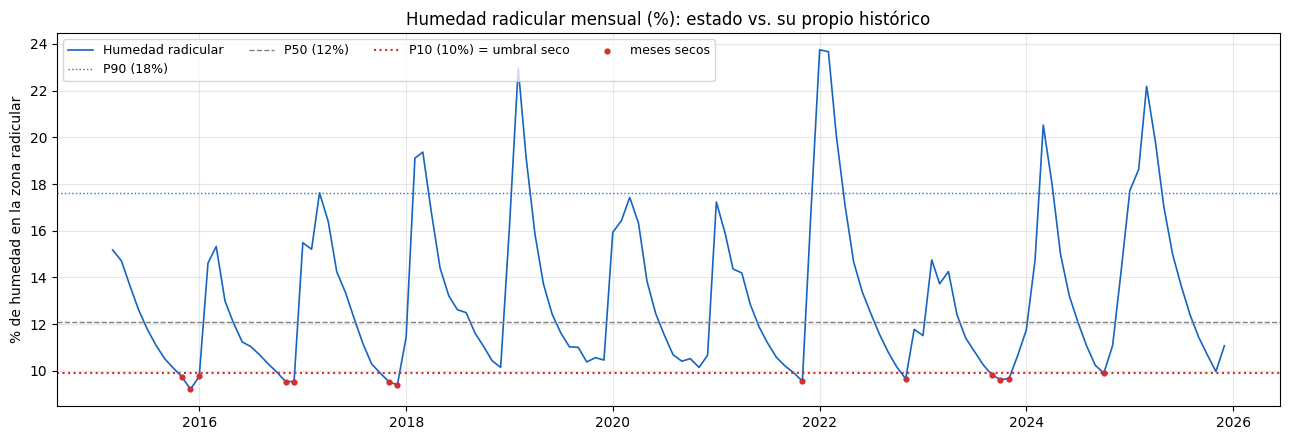

In [14]:
# ============================================================
# M6.1 Humedad radicular: serie mensual y umbrales (SMAP L4)
# ============================================================
# Fix: SMAP arranca en abril 2015 -> hay meses (ene-mar 2015) sin
# imagen. reduceRegion devolvía un dict sin la banda y .get() fallaba.
# Solución: usar dic.get(banda, -9999) y descartar esos valores.
# Además: cada mes ya es UNA imagen reducida -> no hace falta
# trocear; se reduce todo server-side en un solo getInfo.

SMAP_BANDA  = "sm_rootzone"           # humedad radicular (fracción 0-1)
SMAP_PCTL   = "sm_rootzone_pctl"      # percentil histórico (0-100)
SMAP_ANOM   = "sm_surface_anomaly"    # anomalía superficial
ESCALA_SMAP = 10000                   # ~9 km nativo SMAP

co_smap = (
    ee.ImageCollection("NASA/SMAP/SPL4SMGP/008")
    .filterDate(FECHA_INICIO, FECHA_FIN)
    .filterBounds(roi)
)

# SMAP inicia en abril 2015 -> solo años con dato real
anios_smap = list(range(2015, min(ANIOS_COMPLETOS[-1], 2025) + 1))
print(f"Ventana CONFIG: {ANIO_INI}-{ANIOS_COMPLETOS[-1]} (regla 30 años)")
print(f"SMAP con dato real: {anios_smap[0]}-{anios_smap[-1]} ({len(anios_smap)} años)")

# Compuesto mensual: un promedio por año-mes (helper de la sección 1.3)
mensuales = composite_mensual(co_smap, anios_smap, banda=SMAP_BANDA)

# Reducción server-side: un Feature por mes (fecha + valor).
# El valor por defecto (-9999) protege contra meses sin imagen.
def _fecha_valor(img):
    img = ee.Image(img)
    dic = ee.Dictionary(img.reduceRegion(
        ee.Reducer.mean(), roi, ESCALA_SMAP,
        maxPixels=1e9, tileScale=8, bestEffort=True,
    ))
    return ee.Feature(None, {
        "ts": img.get("system:time_start"),
        "v":  dic.get(SMAP_BANDA, -9999),
    })

info = ee.FeatureCollection(mensuales.map(_fecha_valor)).getInfo()

registros = []
for f in info["features"]:
    p = f["properties"]
    v = p.get("v")
    if v is not None and v != -9999:
        registros.append((pd.to_datetime(p["ts"], unit="ms"), v))

serie_sm = pd.Series(dict(registros)).sort_index()
print(f"Meses con dato válido: {len(serie_sm)}")

# SMAP raíz viene en fracción 0-1 -> pasar a % volumétrico
if len(serie_sm) and np.nanmedian(serie_sm.values) <= 1.5:
    serie_sm = 100 * serie_sm

# Percentiles del propio histórico
P10, P50, P90 = np.percentile(serie_sm.values, [10, 50, 90])
df_sm = serie_sm.to_frame("rootzone_pct")
df_sm["seco"] = df_sm["rootzone_pct"] < P10

# Racha máxima de meses secos
def max_racha(lista_bool):
    max_r = r = 0
    for b in lista_bool:
        r = r + 1 if b else 0
        max_r = max(max_r, r)
    return max_r

racha_max_sm = max_racha(list(df_sm["seco"]))

print(f"Humedad radicular: media {serie_sm.mean():.1f}% | "
      f"P10 {P10:.1f}% | P50 {P50:.1f}% | P90 {P90:.1f}%")
print(f"Meses por debajo del P10: {int(df_sm['seco'].sum())} de {len(df_sm)} "
      f"({100 * df_sm['seco'].mean():.0f}%) | máxima racha seca: {racha_max_sm} meses")

display(df_sm.round(1).head())

# --- Gráfico ----------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(df_sm.index, df_sm["rootzone_pct"],
        color="#1565c0", lw=1.2, label="Humedad radicular")
ax.axhline(P90, color="#1976d2", ls=":", lw=1, label=f"P90 ({P90:.0f}%)")
ax.axhline(P50, color="gray",   ls="--", lw=1, label=f"P50 ({P50:.0f}%)")
ax.axhline(P10, color="#d32f2f", ls=":",  lw=1.5,
           label=f"P10 ({P10:.0f}%) = umbral seco")
ax.scatter(df_sm.index[df_sm["seco"]],
           df_sm.loc[df_sm["seco"], "rootzone_pct"],
           c="#d32f2f", s=12, zorder=3, label="meses secos")
ax.set_title("Humedad radicular mensual (%): estado vs. su propio histórico")
ax.set_ylabel("% de humedad en la zona radicular")
ax.legend(ncol=4, fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# ============================================================
# M6.2 Mapas: humedad radicular, percentil y anomalía
#       - Todas las capas RECORTADAS al AOI (.clip(roi))
#       - Visualización clara con colorbars y leyendas explícitas
# ============================================================

SMAP_BANDA  = "sm_rootzone"       # humedad radicular (fracción 0-1)
SMAP_SUP    = "sm_surface"        # humedad superficial (fracción 0-1)
ESCALA_SMAP = 10000               # ~9 km nativo SMAP

co_smap = (
    ee.ImageCollection("NASA/SMAP/SPL4SMGP/008")
    .filterDate(FECHA_INICIO, FECHA_FIN)
    .filterBounds(roi)
)

# --- Fecha real del último dato disponible ---------------------------------
ultima = co_smap.sort("system:time_start", False).first()
ts_ult = ultima.get("system:time_start")
fecha_ultima = ee.Date(ts_ult).format("yyyy-MM-dd").getInfo()
print(f"Último dato SMAP disponible: {fecha_ultima}")

# --- Pares (año, mes) con dato real ----------------------------------------
info_fechas = co_smap.aggregate_array("system:time_start").getInfo()
comb = sorted({
    (pd.to_datetime(t, unit="ms").year, pd.to_datetime(t, unit="ms").month)
    for t in info_fechas
})

def _compuesto(ym, banda):
    y, m = ym
    i0 = f"{y}-{m:02d}-01"
    i1 = (pd.Timestamp(i0) + pd.offsets.MonthBegin(1)).strftime("%Y-%m-%d")
    return (
        co_smap.filterDate(i0, i1).select(banda).mean()
        .set("system:time_start", ee.Date(i0).millis())
    )

ultimo_ym = comb[-1]
mes_ult   = ultimo_ym[1]

# --- 1) ÚLTIMO ESTADO (fracción 0-1) ---------------------------------------
estado_actual = ultima.select(SMAP_BANDA).rename("estado").clip(roi)

# --- 2) PERCENTIL POR PÍXEL (0-100) ----------------------------------------
# Reductor percentile sobre compuestos mensuales: para cada píxel devuelve
# el percentil en que cae el valor del último mes respecto al histórico.
mensuales_root = ee.ImageCollection(
    [_compuesto(ym, SMAP_BANDA) for ym in comb]
)
# Stack de la serie (una banda por mes) para poder calcular percentiles
def _stack(img):
    return ee.Image(img).rename(
        ee.String("b_").cat(
            ee.Date(img.get("system:time_start")).format("YYYYMM")
        )
    )
stack_root = ee.ImageCollection(mensuales_root.map(_stack)).toBands()

# Valor del último mes como imagen de una banda
comp_ult_root = _compuesto(ultimo_ym, SMAP_BANDA).rename("b_ult")

# Percentiles P10, P50, P90 por píxel sobre todo el stack histórico
percentiles = stack_root.reduce(
    ee.Reducer.percentile([10, 50, 90])
).rename(["p10", "p50", "p90"]).clip(roi)

p10 = percentiles.select("p10")
p50 = percentiles.select("p50")
p90 = percentiles.select("p90")

# Posición relativa del último estado en la escala P10–P90 (0–100)
rango   = p90.subtract(p10)
pos_rel = (comp_ult_root.subtract(p10).divide(rango)
           .multiply(100).clamp(0, 100)
           .rename("pos_rel").clip(roi))
pos_rel = pos_rel.updateMask(comp_ult_root.mask())

# --- 3) ANOMALÍA superficial vs. climatología del mismo mes ----------------
comp_ult_sup = _compuesto(ultimo_ym, SMAP_SUP)
clim_mes_sup = ee.ImageCollection(
    [_compuesto(ym, SMAP_SUP) for ym in comb if ym[1] == mes_ult]
).mean()
anomalia = comp_ult_sup.subtract(clim_mes_sup).rename("anomalia").clip(roi)

print(f"Último mes analizado: {ultimo_ym[0]}-{ultimo_ym[1]:02d} "
      f"({MESES_ES[mes_ult - 1]})")
print(f"Anomalía = valor del {MESES_ES[mes_ult - 1]} − "
      f"climatología de {MESES_ES[mes_ult - 1]} (todos los años)")

# --- 4) Promedios del AOI (una llamada por capa) ---------------------------
params_heavy = dict(maxPixels=1e9, tileScale=16, bestEffort=True)

def _mean_aoi(img, banda):
    d = (ee.Image(img).select(banda)
         .reduceRegion(ee.Reducer.mean(), roi, ESCALA_SMAP, **params_heavy)
         .getInfo())
    return d.get(banda)

estado_aoi = _mean_aoi(estado_actual, "estado")
pctl_aoi   = _mean_aoi(pos_rel,       "pos_rel")
anom_aoi   = _mean_aoi(anomalia,      "anomalia")

# Interpretación automática del estado actual
def _etiqueta_estado(pctl):
    if pctl is None:      return "sin dato"
    if pctl < 10:         return "MUY SECO (por debajo del decil más seco)"
    if pctl < 30:         return "seco"
    if pctl < 70:         return "normal"
    if pctl < 90:         return "húmedo"
    return "MUY HÚMEDO (por encima del decil más húmedo)"

print()
print(f"Humedad radicular del AOI : {estado_aoi:.3f} fracción "
      f"({estado_aoi*100:.1f} %)")
print(f"Posición en el histórico  : percentil ~{pctl_aoi:.0f}/100 "
      f"→ {_etiqueta_estado(pctl_aoi)}")
print(f"Anomalía superficial       : {anom_aoi:+.4f} fracción "
      f"({anom_aoi*100:+.2f} %)")

# --- 5) Visualizaciones -----------------------------------------------------
# Humedad (fracción 0-1): rojo = seco, azul = húmedo
vis_hum = {
    "min": 0.05, "max": 0.45,
    "palette": ["a50026", "d73027", "f46d43", "fdae61",
                "fee090", "ffffbf", "abd9e9", "4393c3", "053061"],
}
# Posición relativa (0-100): rojo = seco, azul = húmedo
vis_pos = {
    "min": 0, "max": 100,
    "palette": ["a50026", "d73027", "f46d43", "fdae61",
                "fee090", "ffffbf", "abd9e9", "4393c3", "053061"],
}
# Anomalía (-0.1 a 0.1): marrón = más seco de lo normal, azul = más húmedo
vis_anom = {
    "min": -0.10, "max": 0.10,
    "palette": ["a50026", "f46d43", "fddbc7", "f7f7f7",
                "d1e5f0", "4393c3", "053061"],
}

Map_m6 = geemap.Map()
Map_m6.centerObject(roi, ZONA["zoom"])
Map_m6.add_basemap("HYBRID")

# Capa 1 (visible): último estado radicular
Map_m6.addLayer(
    estado_actual, vis_hum,
    f"1) Último estado radicular ({fecha_ultima})",
)

# Capa 2 (visible): percentil por píxel — la más intuitiva
Map_m6.addLayer(
    pos_rel, vis_pos,
    f"2) Percentil histórico (0=seco, 100=húmedo) — {ultimo_ym[0]}-{ultimo_ym[1]:02d}",
)

# Capa 3 (apagada): anomalía superficial
Map_m6.addLayer(
    anomalia, vis_anom,
    f"3) Anomalía superficial vs. {MESES_ES[mes_ult-1]} típico",
    False,
)

# Borde del AOI siempre por encima
Map_m6.addLayer(borde_aoi(color="FF0000", ancho=2), {}, "AOI (GeoJSON)")

# Colorbars
Map_m6.add_colorbar(
    vis_hum, label="Humedad radicular (fracción 0–1)",
    orientation="horizontal", position="bottomright",
    layer_name="1) Último estado radicular",
)
Map_m6.add_colorbar(
    vis_pos, label="Percentil (0 = muy seco · 100 = muy húmedo)",
    orientation="horizontal", position="bottomright",
    layer_name="2) Percentil histórico",
)

# --- 6) Toolbar de inspección: click para ver valores puntuales -------------
import ipywidgets as widgets
from IPython.display import display

inspector = widgets.Output(layout={"border": "1px solid #ccc",
                                    "padding": "6px",
                                    "max_height": "150px",
                                    "overflow": "auto"})

def _handle_click(**kwargs):
    if kwargs.get("type") != "click":
        return
    coords = kwargs.get("coordinates")
    if not coords:
        return
    pt = ee.Geometry.Point(coords)
    v_est = (estado_actual.reduceRegion(ee.Reducer.first(), pt, ESCALA_SMAP)
             .getInfo().get("estado"))
    v_pct = (pos_rel.reduceRegion(ee.Reducer.first(), pt, ESCALA_SMAP)
             .getInfo().get("pos_rel"))
    v_anm = (anomalia.reduceRegion(ee.Reducer.first(), pt, ESCALA_SMAP)
             .getInfo().get("anomalia"))
    with inspector:
        inspector.clear_output()
        print(f"📍 Punto: {coords[1]:.4f}, {coords[0]:.4f}")
        if v_est is not None:
            print(f"   Humedad radicular : {v_est:.3f} ({v_est*100:.1f} %)")
        else:
            print("   Humedad radicular : sin dato")
        if v_pct is not None:
            print(f"   Percentil         : {v_pct:.0f}/100 "
                  f"({_etiqueta_estado(v_pct)})")
        else:
            print("   Percentil         : sin dato")
        if v_anm is not None:
            print(f"   Anomalía          : {v_anm*100:+.2f} pp")
        else:
            print("   Anomalía          : sin dato")

Map_m6.on_interaction(_handle_click)

display(Map_m6)
display(inspector)

Último dato SMAP disponible: 2026-10-12
Último mes analizado: 2026-10 (Oct)
Anomalía = valor del Oct − climatología de Oct (todos los años)

Humedad radicular del AOI : 0.112 fracción (11.2 %)
Posición en el histórico  : percentil ~43/100 → normal
Anomalía superficial       : +0.0222 fracción (+2.22 %)


Map(center=[-19.436538457151876, -67.61413826547425], controls=(WidgetControl(options=['position', 'transparen…

Output(layout=Layout(border='1px solid #ccc', max_height='150px', overflow='auto', padding='6px'))

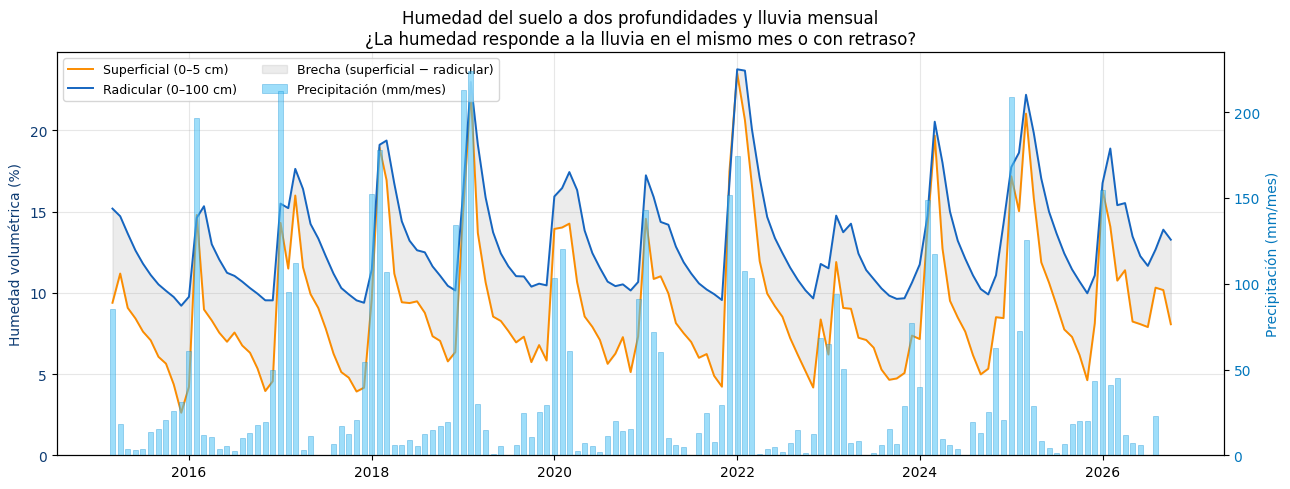

Brecha media superficial − radicular: -4.06 pp
Meses en que superficial > radicular: 2 / 140

Correlación humedad ~ lluvia (mismo mes / mes anterior):
  Superficial : r = +0.69  /  +0.70
  Radicular   : r = +0.53  /  +0.76


In [28]:
# ============================================================
# M6.3 Humedad superficial (0-5 cm) vs. radicular (0-100 cm)
#      + Precipitación mensual (CHIRPS) en eje secundario normal
# ============================================================

# ---------- 1) Series de humedad --------------------------------------------
def _serie_mensual(banda):
    """Serie mensual del AOI para una banda SMAP -> pd.Series."""
    def _v(img):
        img = ee.Image(img)
        d = ee.Dictionary(img.reduceRegion(
            ee.Reducer.mean(), roi, ESCALA_SMAP,
            maxPixels=1e9, tileScale=16, bestEffort=True,
        ))
        return ee.Feature(None, {
            "ts": img.get("system:time_start"),
            "v":  d.get(banda, -9999),
        })
    fc = ee.FeatureCollection(
        ee.ImageCollection([_compuesto(ym, banda) for ym in comb]).map(_v)
    ).getInfo()
    regs = [(pd.to_datetime(f["properties"]["ts"], unit="ms"),
             f["properties"]["v"]) for f in fc["features"]
            if f["properties"]["v"] not in (None, -9999)]
    s = pd.Series(dict(regs)).sort_index()
    if len(s) and np.nanmedian(s.values) <= 1.5:
        s = 100 * s
    return s

sup  = _serie_mensual("sm_surface")
root = _serie_mensual("sm_rootzone")

df_2capas = pd.DataFrame({"superficial_%": sup, "radicular_%": root}).dropna()

# ---------- 2) Lluvia mensual del AOI (CHIRPS) ------------------------------
_anios_pp = sorted({ym[0] for ym in comb})

chirps = (
    ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
    .filterDate(f"{_anios_pp[0]}-01-01", FECHA_FIN)
    .filterBounds(roi)
)

pp_mensual = composite_mensual(chirps, _anios_pp, banda="precipitation")

def _suma_aoi(img):
    img = ee.Image(img)
    d = ee.Dictionary(img.reduceRegion(
        ee.Reducer.sum(), roi, ESCALA_SMAP,
        maxPixels=1e9, tileScale=16, bestEffort=True,
    ))
    return ee.Feature(None, {
        "ts": img.get("system:time_start"),
        "p":  d.get("precipitation", -9999),
    })

fc_pp = ee.FeatureCollection(pp_mensual.map(_suma_aoi)).getInfo()
pp = pd.Series({
    pd.to_datetime(f["properties"]["ts"], unit="ms"): f["properties"]["p"]
    for f in fc_pp["features"]
    if f["properties"]["p"] not in (None, -9999)
}).sort_index()

# Alinear al mismo índice que las curvas
pp = pp.reindex(df_2capas.index)

# ---------- 3) Gráfico combinado --------------------------------------------
fig, ax = plt.subplots(figsize=(13, 5))

# 3a) Curvas de humedad (eje izquierdo)
ax.plot(df_2capas.index, df_2capas["superficial_%"],
        color="#fb8c00", lw=1.4, label="Superficial (0–5 cm)")
ax.plot(df_2capas.index, df_2capas["radicular_%"],
        color="#1565c0", lw=1.4, label="Radicular (0–100 cm)")
ax.fill_between(df_2capas.index,
                df_2capas["radicular_%"], df_2capas["superficial_%"],
                color="gray", alpha=0.15,
                label="Brecha (superficial − radicular)")

ax.set_ylabel("Humedad volumétrica (%)", color="#0d3b73")
ax.set_ylim(bottom=0)
ax.tick_params(axis="y", labelcolor="#0d3b73")
ax.grid(alpha=0.3)

# 3b) Barras de precipitación (eje derecho, normal)
ax2 = ax.twinx()
ax2.bar(pp.index, pp.values,
        width=20,                 # ~3 semanas de ancho
        color="#4fc3f7", alpha=0.55,
        edgecolor="#0288d1", linewidth=0.4,
        label="Precipitación (mm/mes)")
ax2.set_ylabel("Precipitación (mm/mes)", color="#0277bd")
ax2.set_ylim(bottom=0)             # <- sin inversión, barras hacia arriba
ax2.tick_params(axis="y", labelcolor="#0277bd")

# 3c) Leyenda unificada
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9, ncol=2)

ax.set_title("Humedad del suelo a dos profundidades y lluvia mensual\n"
             "¿La humedad responde a la lluvia en el mismo mes o con retraso?")
plt.tight_layout()
plt.show()

# ---------- 4) Estadísticas rápidas -----------------------------------------
brecha = df_2capas["superficial_%"] - df_2capas["radicular_%"]
print(f"Brecha media superficial − radicular: {brecha.mean():+.2f} pp")
print(f"Meses en que superficial > radicular: "
      f"{int((brecha > 0).sum())} / {len(brecha)}")

# Correlación humedad ~ lluvia del mismo mes y del mes anterior
pares = pd.DataFrame({"sup":  df_2capas["superficial_%"],
                      "root": df_2capas["radicular_%"],
                      "pp":   pp}).dropna()
if len(pares) > 6:
    r_sup_0  = pares["sup"].corr(pares["pp"])
    r_sup_1  = pares["sup"].corr(pares["pp"].shift(1))
    r_root_0 = pares["root"].corr(pares["pp"])
    r_root_1 = pares["root"].corr(pares["pp"].shift(1))
    print(f"\nCorrelación humedad ~ lluvia (mismo mes / mes anterior):")
    print(f"  Superficial : r = {r_sup_0:+.2f}  /  {r_sup_1:+.2f}")
    print(f"  Radicular   : r = {r_root_0:+.2f}  /  {r_root_1:+.2f}")

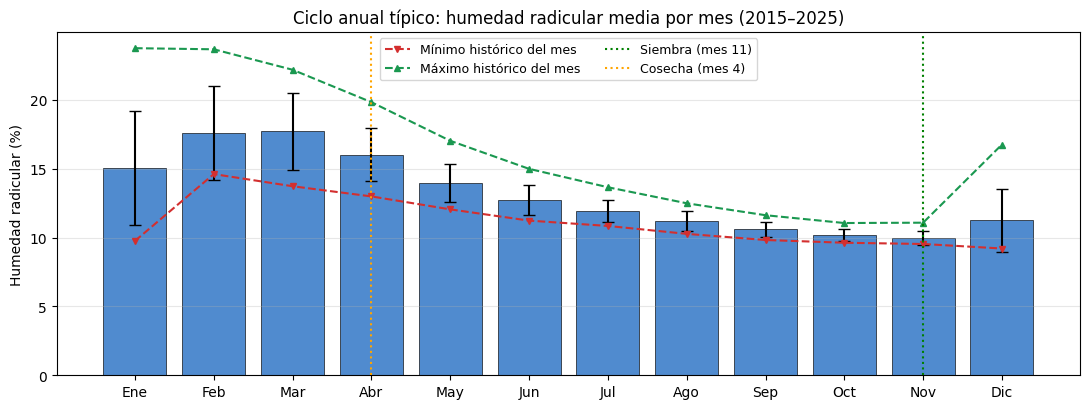

Mes más seco en promedio : Nov (10.0%)
Mes más húmedo en promedio: Mar (17.7%)
Amplitud estacional: 7.7 pp


In [19]:
# ============================================================
# M6.4 Climatología mensual de la humedad radicular
# ============================================================
# Para cada mes (1-12) se promedia TODOS los años disponibles.
# Muestra el ciclo anual típico: qué mes es el más seco, cuál el más húmedo.

df_clim = df_sm.copy()
df_clim["mes"] = df_clim.index.month
clim = df_clim.groupby("mes")["rootzone_pct"].agg(["mean", "std", "min", "max"])

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(clim.index, clim["mean"], yerr=clim["std"], capsize=4,
       color="#1565c0", alpha=0.75, edgecolor="black", linewidth=0.6)
ax.plot(clim.index, clim["min"], "v--", color="#d32f2f",
        ms=5, label="Mínimo histórico del mes")
ax.plot(clim.index, clim["max"], "^--", color="#1a9850",
        ms=5, label="Máximo histórico del mes")

# Marcar siembra y cosecha
ax.axvline(CALENDARIO["siembra"], color="green", ls=":",
           label=f"Siembra (mes {CALENDARIO['siembra']})")
ax.axvline(CALENDARIO["cosecha"], color="orange", ls=":",
           label=f"Cosecha (mes {CALENDARIO['cosecha']})")

ax.set_xticks(MESES)
ax.set_xticklabels(MESES_ES)
ax.set_ylabel("Humedad radicular (%)")
ax.set_title("Ciclo anual típico: humedad radicular media por mes (2015–2025)")
ax.legend(fontsize=9, ncol=2)
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

mes_seco = int(clim["mean"].idxmin())
mes_hum  = int(clim["mean"].idxmax())
print(f"Mes más seco en promedio : {MESES_ES[mes_seco-1]} ({clim['mean'].min():.1f}%)")
print(f"Mes más húmedo en promedio: {MESES_ES[mes_hum-1]} ({clim['mean'].max():.1f}%)")
print(f"Amplitud estacional: {clim['mean'].max() - clim['mean'].min():.1f} pp")

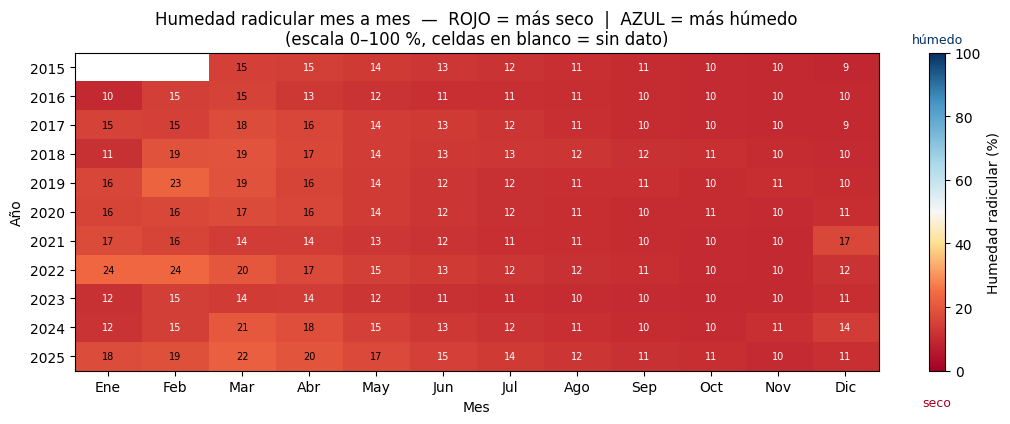

Años con más meses bajo el P10:
anio
2016    3
2023    3
2015    2
2017    2
2021    1


In [26]:
# ============================================================
# M6.5 Heatmap años × meses de humedad radicular
# Escala divergente:  0 % = rojo (seco)  ->  100 % = azul (húmedo)
# ============================================================

from matplotlib.colors import LinearSegmentedColormap

# Paleta rojo -> amarillo -> blanco -> celeste -> azul
# Anclas pensadas para que el punto medio (~50 %) caiga en blanco.
cmap_humedad = LinearSegmentedColormap.from_list(
    "humedad_rojo_azul",
    [
        (0.00, "#a50026"),   # 0 %   rojo oscuro  (muy seco)
        (0.25, "#f46d43"),   # 25 %  naranja
        (0.40, "#fee090"),   # 40 %  amarillo claro
        (0.50, "#f7f7f7"),   # 50 %  blanco (punto neutro)
        (0.65, "#abd9e9"),   # 65 %  celeste
        (0.85, "#4393c3"),   # 85 %  azul medio
        (1.00, "#053061"),   # 100 % azul oscuro (muy húmedo)
    ],
)

# --- Matriz años × meses ----------------------------------------------------
pivote = df_sm["rootzone_pct"].to_frame()
pivote["anio"] = pivote.index.year
pivote["mes"]  = pivote.index.month
matriz = pivote.pivot_table(index="anio", columns="mes",
                            values="rootzone_pct")
matriz = matriz.reindex(columns=MESES)

# --- Escala fija 0–100 ------------------------------------------------------
vmin, vmax = 0, 100

fig, ax = plt.subplots(figsize=(11, 0.5 + 0.35 * len(matriz)))
im = ax.imshow(matriz.values, aspect="auto", cmap=cmap_humedad,
               vmin=vmin, vmax=vmax)

ax.set_xticks(range(12)); ax.set_xticklabels(MESES_ES)
ax.set_yticks(range(len(matriz))); ax.set_yticklabels(matriz.index)
ax.set_xlabel("Mes"); ax.set_ylabel("Año")
ax.set_title("Humedad radicular mes a mes  —  "
             "ROJO = más seco  |  AZUL = más húmedo\n"
             "(escala 0–100 %, celdas en blanco = sin dato)")

# --- Números dentro de cada celda, con color de texto adaptativo -----------
for i in range(len(matriz)):
    for j in range(12):
        v = matriz.values[i, j]
        if np.isnan(v):
            continue
        # Cerca de 0 y de 100 el fondo es oscuro -> texto blanco.
        # Cerca de 50 el fondo es claro -> texto negro.
        frac = (v - vmin) / (vmax - vmin)
        color_texto = "white" if (frac < 0.15 or frac > 0.85) else "black"
        ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                fontsize=7, color=color_texto)

# --- Colorbar ---------------------------------------------------------------
cbar = plt.colorbar(im, ax=ax,
                    ticks=[0, 20, 40, 60, 80, 100],
                    label="Humedad radicular (%)")
cbar.ax.text(0.5, -0.08, "seco", transform=cbar.ax.transAxes,
             ha="center", va="top",    fontsize=9, color="#a50026")
cbar.ax.text(0.5,  1.02, "húmedo", transform=cbar.ax.transAxes,
             ha="center", va="bottom", fontsize=9, color="#053061")

plt.tight_layout()
plt.show()

# --- Años con más meses secos ----------------------------------------------
df_sm["anio"] = df_sm.index.year
secos_por_anio = (
    df_sm[df_sm["seco"]].groupby("anio").size()
    .sort_values(ascending=False)
)
print("Años con más meses bajo el P10:")
print(secos_por_anio.head(5).to_string())

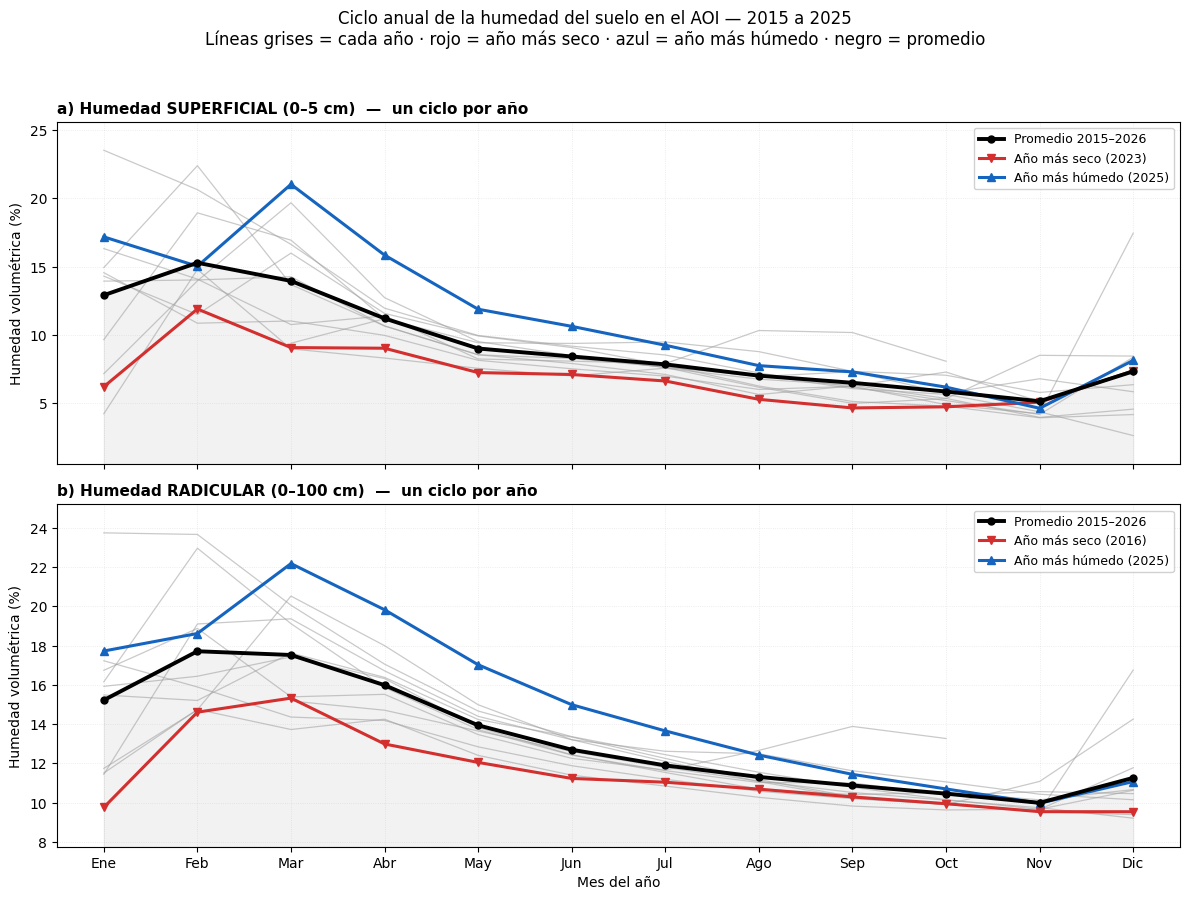

Año más seco   (superficial): 2023
Año más seco   (radicular)  : 2016
Año más húmedo (superficial): 2025
Año más húmedo (radicular)  : 2025

Mes más seco   (promedio superficial): Nov
Mes más seco   (promedio radicular)  : Nov
Mes más húmedo (promedio superficial): Feb
Mes más húmedo (promedio radicular)  : Feb


In [35]:
# ============================================================
# M6.9 Ciclo anual de humedad del suelo a dos profundidades
#      Una línea por año, destacando: año más seco, más húmedo
#      y promedio. X = meses (Ene-Dic).
# ============================================================

def _serie_mensual(banda):
    """Serie mensual del AOI para una banda SMAP -> pd.Series."""
    def _v(img):
        img = ee.Image(img)
        d = ee.Dictionary(img.reduceRegion(
            ee.Reducer.mean(), roi, ESCALA_SMAP,
            maxPixels=1e9, tileScale=16, bestEffort=True,
        ))
        return ee.Feature(None, {
            "ts": img.get("system:time_start"),
            "v":  d.get(banda, -9999),
        })
    fc = ee.FeatureCollection(
        ee.ImageCollection([_compuesto(ym, banda) for ym in comb]).map(_v)
    ).getInfo()
    regs = [(pd.to_datetime(f["properties"]["ts"], unit="ms"),
             f["properties"]["v"]) for f in fc["features"]
            if f["properties"]["v"] not in (None, -9999)]
    s = pd.Series(dict(regs)).sort_index()
    if len(s) and np.nanmedian(s.values) <= 1.5:
        s = 100 * s
    return s

# --- Series a las dos profundidades -----------------------------------------
sup  = _serie_mensual("sm_surface")
root = _serie_mensual("sm_rootzone")

# --- Matriz meses × años para cada profundidad ------------------------------
def _matriz_anual(serie):
    df = serie.to_frame("v")
    df["anio"] = df.index.year
    df["mes"]  = df.index.month
    return df.pivot_table(index="anio", columns="mes", values="v")

mat_sup  = _matriz_anual(sup)
mat_root = _matriz_anual(root)

# --- Función para dibujar un panel ------------------------------------------
def _panel_ciclo(ax, matriz, titulo, unidad="%"):
    meses = np.arange(1, 13)

    # Escala Y (dejar margen arriba y abajo)
    vmin = np.nanmin(matriz.values)
    vmax = np.nanmax(matriz.values)
    margen = 0.10 * (vmax - vmin)
    ax.set_ylim(vmin - margen, vmax + margen)

    # 1) TODAS las líneas en gris claro
    for anio, fila in matriz.iterrows():
        ax.plot(meses, fila.values, color="#9e9e9e",
                lw=0.9, alpha=0.55, zorder=1)

    # 2) Identificar año más seco / más húmedo / promedio
    #    Criterio: promedio anual dentro del AOI
    prom_anual = matriz.mean(axis=1, skipna=True)
    anio_seco = int(prom_anual.idxmin())
    anio_hum  = int(prom_anual.idxmax())
    fila_prom = matriz.mean(axis=0, skipna=True)   # promedio por mes

    # 3) Línea del PROMEDIO (negro grueso)
    ax.plot(meses, fila_prom.values, color="black", lw=2.8,
            marker="o", ms=5, zorder=4,
            label=f"Promedio {matriz.index.min()}–{matriz.index.max()}")

    # 4) Línea del año MÁS SECO (rojo)
    ax.plot(meses, matriz.loc[anio_seco].values,
            color="#d32f2f", lw=2.2, marker="v", ms=6, zorder=3,
            label=f"Año más seco ({anio_seco})")

    # 5) Línea del año MÁS HÚMEDO (azul)
    ax.plot(meses, matriz.loc[anio_hum].values,
            color="#1565c0", lw=2.2, marker="^", ms=6, zorder=3,
            label=f"Año más húmedo ({anio_hum})")

    # 6) Sombreado bajo el promedio (referencia visual)
    ax.fill_between(meses, vmin - margen, fila_prom.values,
                    color="black", alpha=0.05, zorder=0)

    # 7) Ejes y decoración
    ax.set_xticks(meses)
    ax.set_xticklabels(MESES_ES)
    ax.set_xlim(0.5, 12.5)
    ax.set_ylabel(f"Humedad volumétrica ({unidad})")
    ax.set_title(titulo, loc="left", fontsize=11, fontweight="bold")
    ax.grid(alpha=0.3, linestyle=":", linewidth=0.6)
    ax.legend(loc="upper right", fontsize=9, framealpha=0.9)

# --- Figura con dos paneles apilados ----------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

_panel_ciclo(
    axes[0], mat_sup,
    "a) Humedad SUPERFICIAL (0–5 cm)  —  un ciclo por año",
)
_panel_ciclo(
    axes[1], mat_root,
    "b) Humedad RADICULAR (0–100 cm)  —  un ciclo por año",
)

axes[1].set_xlabel("Mes del año")

fig.suptitle(
    "Ciclo anual de la humedad del suelo en el AOI — 2015 a 2025\n"
    "Líneas grises = cada año · rojo = año más seco · azul = año más húmedo · "
    "negro = promedio",
    fontsize=12, y=0.995,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# --- Tabla resumen ----------------------------------------------------------
print(f"Año más seco   (superficial): {int(mat_sup.mean(axis=1).idxmin())}")
print(f"Año más seco   (radicular)  : {int(mat_root.mean(axis=1).idxmin())}")
print(f"Año más húmedo (superficial): {int(mat_sup.mean(axis=1).idxmax())}")
print(f"Año más húmedo (radicular)  : {int(mat_root.mean(axis=1).idxmax())}")
print()
print(f"Mes más seco   (promedio superficial): "
      f"{MESES_ES[mat_sup.mean(axis=0).idxmin() - 1]}")
print(f"Mes más seco   (promedio radicular)  : "
      f"{MESES_ES[mat_root.mean(axis=0).idxmin() - 1]}")
print(f"Mes más húmedo (promedio superficial): "
      f"{MESES_ES[mat_sup.mean(axis=0).idxmax() - 1]}")
print(f"Mes más húmedo (promedio radicular)  : "
      f"{MESES_ES[mat_root.mean(axis=0).idxmax() - 1]}")

## Interpretación de M6
* **Percentil bajo (< 10)** en la zona radicular = condición entre las más secas del histórico:
  es la señal accionable para riego o alerta temprana (complementa el SPI de M5, que mide lluvia).
* **Anomalía negativa persistente** varias semanas = sequía de suelo en desarrollo aunque llueva
  poco; la atmósfera y el suelo se desacoplan.
* **Duración:** la máxima racha de meses por debajo del P10 (impresa arriba) mide eventos largos.
* La ventana con dato real de SMAP es **2015–actual**; para 30 años completos usar la
  alternativa ERA5-Land comentada en M6.1.

**Preguntas guía**
1. ¿Los meses que ustedes marcan como "secos en el campo" caen bajo el P10 en la serie?
2. ¿La anomalía reciente coincide con lo que miden sus sensores de humedad de suelo (CLIMBAT/PACHASOL)?
3. ¿Qué años con menor NDVI (M7) muestran aquí los percentiles más bajos?

## Cierre: checklist del modulo

- [ ] Parte base ejecutada (instalacion, autenticacion GEE, CONFIG, AOI del GeoJSON).
- [ ] Mapa(s) revisados contra el borde rojo del AOI (el GeoJSON siempre manda).
- [ ] Serie/tabla leidas + interpretacion contrastada con saber local (Yapuchiri/PACHASOL).
- [ ] Periodo y dataset anotados junto a cada numero (p. ej. `CHIRPS 1981-2025`).

### Como cambiar de satelite o de anos (patron en todos los modulos)

```python
FECHA_INICIO = "1996-01-01"  # en la celda CONFIG: ventana analitica
FECHA_FIN = "2026-12-31"
# --- Primario (default) ---
precip = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
# --- Alternativas: comentar la primaria y descomentar la elegida ---
# precip = ee.ImageCollection("NASA/GPM_L3/IMERG_V06")
# Cada alternativa indica resolucion, periodo y para que sirve.
```
